# ¡Llena ese carrito!

# Introducción

Instacart es una plataforma de entregas de comestibles donde la clientela puede registrar un pedido y hacer que se lo entreguen, similar a Uber Eats y Door Dash.
El conjunto de datos que te hemos proporcionado tiene modificaciones del original. Redujimos el tamaño del conjunto para que tus cálculos se hicieran más rápido e introdujimos valores ausentes y duplicados. Tuvimos cuidado de conservar las distribuciones de los datos originales cuando hicimos los cambios.

Debes completar tres pasos. Para cada uno de ellos, escribe una breve introducción que refleje con claridad cómo pretendes resolver cada paso, y escribe párrafos explicatorios que justifiquen tus decisiones al tiempo que avanzas en tu solución.  También escribe una conclusión que resuma tus hallazgos y elecciones.


## Diccionario de datos

Hay cinco tablas en el conjunto de datos, y tendrás que usarlas todas para hacer el preprocesamiento de datos y el análisis exploratorio de datos. A continuación se muestra un diccionario de datos que enumera las columnas de cada tabla y describe los datos que contienen.

- `instacart_orders.csv`: cada fila corresponde a un pedido en la aplicación Instacart.
    - `'order_id'`: número de ID que identifica de manera única cada pedido.
    - `'user_id'`: número de ID que identifica de manera única la cuenta de cada cliente.
    - `'order_number'`: el número de veces que este cliente ha hecho un pedido.
    - `'order_dow'`: día de la semana en que se hizo el pedido (0 si es domingo).
    - `'order_hour_of_day'`: hora del día en que se hizo el pedido.
    - `'days_since_prior_order'`: número de días transcurridos desde que este cliente hizo su pedido anterior.
- `products.csv`: cada fila corresponde a un producto único que pueden comprar los clientes.
    - `'product_id'`: número ID que identifica de manera única cada producto.
    - `'product_name'`: nombre del producto.
    - `'aisle_id'`: número ID que identifica de manera única cada categoría de pasillo de víveres.
    - `'department_id'`: número ID que identifica de manera única cada departamento de víveres.
- `order_products.csv`: cada fila corresponde a un artículo pedido en un pedido.
    - `'order_id'`: número de ID que identifica de manera única cada pedido.
    - `'product_id'`: número ID que identifica de manera única cada producto.
    - `'add_to_cart_order'`: el orden secuencial en el que se añadió cada artículo en el carrito.
    - `'reordered'`: 0 si el cliente nunca ha pedido este producto antes, 1 si lo ha pedido.
- `aisles.csv`
    - `'aisle_id'`: número ID que identifica de manera única cada categoría de pasillo de víveres.
    - `'aisle'`: nombre del pasillo.
- `departments.csv`
    - `'department_id'`: número ID que identifica de manera única cada departamento de víveres.
    - `'department'`: nombre del departamento.

# Paso 1. Descripción de los datos

Lee los archivos de datos (`/datasets/instacart_orders.csv`, `/datasets/products.csv`, `/datasets/aisles.csv`, `/datasets/departments.csv` y `/datasets/order_products.csv`) con `pd.read_csv()` usando los parámetros adecuados para leer los datos correctamente. Verifica la información para cada DataFrame creado.


## Plan de solución

Escribe aquí tu plan de solución para el Paso 1. Descripción de los datos.

In [1]:
# importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# leer conjuntos de datos en los DataFrames
df_orders = pd.read_csv("/datasets/instacart_orders.csv", sep=";")
df_products = pd.read_csv("/datasets/products.csv", sep=";")
df_aisles = pd.read_csv("/datasets/aisles.csv", sep=";")
df_departments = pd.read_csv("/datasets/departments.csv", sep=";")
df_order_products = pd.read_csv("/datasets/order_products.csv", sep=";")

In [3]:
# mostrar información del DataFrame
df_orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478967 entries, 0 to 478966
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                478967 non-null  int64  
 1   user_id                 478967 non-null  int64  
 2   order_number            478967 non-null  int64  
 3   order_dow               478967 non-null  int64  
 4   order_hour_of_day       478967 non-null  int64  
 5   days_since_prior_order  450148 non-null  float64
dtypes: float64(1), int64(5)
memory usage: 21.9 MB


In [4]:
# mostrar información del DataFrame
df_products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     49694 non-null  int64 
 1   product_name   48436 non-null  object
 2   aisle_id       49694 non-null  int64 
 3   department_id  49694 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB


In [5]:
# mostrar información del DataFrame
df_aisles.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   aisle_id  134 non-null    int64 
 1   aisle     134 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.2+ KB


In [6]:
# mostrar información del DataFrame
df_departments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   department_id  21 non-null     int64 
 1   department     21 non-null     object
dtypes: int64(1), object(1)
memory usage: 464.0+ bytes


In [7]:
# mostrar información del DataFrame
df_order_products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Dtype  
---  ------             -----  
 0   order_id           int64  
 1   product_id         int64  
 2   add_to_cart_order  float64
 3   reordered          int64  
dtypes: float64(1), int64(3)
memory usage: 138.7 MB


## Conclusiones

En esta fase se importaron las librerías necesarias para el análisis y visualización de datos, y posteriormente se cargaron cinco conjuntos de datos en DataFrames de Pandas. Además, se utilizó el método `.info()` para revisar la estructura de cada tabla, identificando tipos de datos, cantidad de registros y posibles valores nulos antes de comenzar el procesamiento de la información.



# Paso 2. Preprocesamiento de los datos

Preprocesa los datos de la siguiente manera:

- Verifica y corrige los tipos de datos (por ejemplo, asegúrate de que las columnas de ID sean números enteros).
- Identifica y completa los valores ausentes.
- Identifica y elimina los valores duplicados.

Asegúrate de explicar qué tipos de valores ausentes y duplicados encontraste, cómo los completaste o eliminaste y por qué usaste esos métodos. ¿Por qué crees que estos valores ausentes y duplicados pueden haber estado presentes en el conjunto de datos?

## Plan de solución

Para abordar los problemas de calidad en los datos, se planteó una estrategia enfocada en la detección y tratamiento de registros duplicados y valores ausentes en los distintos DataFrames del proyecto. El plan consistió en revisar la integridad de cada tabla, validar identificadores únicos y analizar posibles patrones en los datos faltantes antes de realizar cualquier modificación.

Posteriormente, se propuso eliminar duplicados cuando afectaran la consistencia de la información, conservar los valores nulos que representaran situaciones lógicas dentro del contexto de los datos y reemplazar aquellos faltantes que pudieran dificultar el análisis posterior. Finalmente, se realizarían verificaciones adicionales para confirmar que las transformaciones aplicadas mantuvieran la coherencia y confiabilidad del conjunto de datos.

## Encuentra y elimina los valores duplicados (y describe cómo tomaste tus decisiones).

### `orders` data frame

In [8]:
# Revisa si hay pedidos duplicados
df_orders.duplicated().sum()

15

¿Tienes líneas duplicadas? Si sí, ¿qué tienen en común?

In [9]:
# Basándote en tus hallazgos,
# Verifica todos los pedidos que se hicieron el miércoles a las 2:00 a.m.
pedidos_del_miercoles_2am = df_orders[(df_orders["order_dow"] == 3) & (df_orders["order_hour_of_day"] == 2)]
print(pedidos_del_miercoles_2am)

        order_id  user_id  order_number  order_dow  order_hour_of_day  \
4838     2766110   162084            41          3                  2   
5156     2190225   138285            18          3                  2   
15506     553049    58599            13          3                  2   
18420     382357   120200            19          3                  2   
24691     690242    77357             2          3                  2   
...          ...      ...           ...        ...                ...   
457013   3384021    14881             6          3                  2   
458816    910166   164782            18          3                  2   
459635   1680532   106435             6          3                  2   
468324    222962    54979            59          3                  2   
477526   2592344    46860            38          3                  2   

        days_since_prior_order  
4838                      16.0  
5156                      11.0  
15506                   

Este resultado sugiere que los registros duplicados identificados anteriormente estaban concentrados en pedidos realizados el miércoles a las 2:00 a.m. Esto indica que probablemente existió un problema específico durante el registro o almacenamiento de datos en ese horario, generando múltiples entradas repetidas para los mismos pedidos.


In [10]:
# Elimina los pedidos duplicados
df_orders = df_orders.drop_duplicates(subset=["order_id"])

In [11]:
# Vuelve a verificar si hay filas duplicadas
df_orders.duplicated().sum()

0

In [12]:
# Vuelve a verificar únicamente si hay IDs duplicados de pedidos
df_orders["order_id"].duplicated().sum()

0

En esta fase se analizaron y eliminaron registros duplicados en el DataFrame df_orders. Para ello, se revisaron específicamente los pedidos realizados el miércoles a las 2:00 a.m. y posteriormente se eliminaron las filas repetidas utilizando order_id como identificador único, verificando al final que no quedaran duplicados en los datos.

### `products` data frame

In [13]:
# Verifica si hay filas totalmente duplicadas
df_products.duplicated().sum()

0

In [14]:
# Revisa únicamente si hay ID de productos duplicados
df_products["product_id"].duplicated().sum()

0

In [15]:
# Revisa únicamente si hay nombres duplicados de productos (convierte los nombres a letras mayúsculas para compararlos mejor)
df_products["product_name"].str.upper().duplicated().sum()

1361

In [16]:
# Revisa si hay nombres duplicados de productos no faltantes
df_products.dropna(subset=["product_name"])["product_name"].str.upper().duplicated().sum()

104

En esta etapa se verificó la existencia de datos duplicados en el DataFrame `df_products`, analizando tanto filas completas como identificadores y nombres de productos. Además, los nombres fueron convertidos a mayúsculas para realizar una comparación más precisa y detectar duplicados independientemente del formato del texto.

### `departments` data frame

In [17]:
# Revisa si hay filas totalmente duplicadas
df_departments.duplicated().sum()

0

In [18]:
# Revisa únicamente si hay IDs duplicadas de departamentos
# Revisa si hay filas totalmente duplicadas
df_departments["department_id"].duplicated().sum()

0

En esta fase se revisó el DataFrame df_departments para identificar posibles registros duplicados, tanto a nivel de filas completas como en los identificadores únicos de cada departamento, asegurando la consistencia de la información.

### `aisles` data frame

In [19]:
# Revisa si hay filas totalmente duplicadas
df_aisles.duplicated().sum()

0

In [20]:
# Revisa únicamente si hay IDs duplicadas de pasillos
df_aisles["aisle_id"].duplicated().sum()

0

En esta etapa se verificó la presencia de registros duplicados en el DataFrame `df_aisles`, revisando tanto filas completas como los identificadores únicos de los pasillos para garantizar la integridad de los datos.

### `order_products` data frame

In [21]:
# Revisa si hay filas totalmente duplicadas
df_order_products.duplicated().sum()

0

In [22]:
# Vuelve a verificar si hay cualquier otro duplicado engañoso
df_order_products[["order_id", "product_id"]].duplicated().sum()

0

En esta fase se analizaron posibles duplicados en el DataFrame `df_order_products`, revisando tanto filas completamente repetidas como combinaciones de `order_id` y `product_id`, con el fin de detectar registros redundantes que pudieran afectar el análisis posterior.

## Encuentra y elimina los valores ausentes

Al trabajar con valores duplicados, pudimos observar que también nos falta investigar valores ausentes:

* La columna `'product_name'` de la tabla products.
* La columna `'days_since_prior_order'` de la tabla orders.
* La columna `'add_to_cart_order'` de la tabla order_productos.

### `products` data frame

In [23]:
# Encuentra los valores ausentes en la columna 'product_name'
df_products["product_name"].isna().sum()

1258

En esta etapa se identificaron los valores ausentes en la columna `product_name` del DataFrame `df_products`, con el objetivo de evaluar la calidad de los datos y detectar posibles registros incompletos.


In [24]:
#  ¿Todos los nombres de productos ausentes están relacionados con el pasillo con ID 100?
df_products[df_products["product_name"].isna()]

,product_id,product_name,aisle_id,department_id
37,38,NaN,100,21
71,72,NaN,100,21
109,110,NaN,100,21
296,297,NaN,100,21
416,417,NaN,100,21
...,...,...,...,...
49552,49553,NaN,100,21
49574,49575,NaN,100,21
49640,49641,NaN,100,21
49663,49664,NaN,100,21


En esta fase se analizaron los registros con nombres de productos ausentes para verificar su relación con el pasillo de ID 100. Tras la revisión, se confirmó que todos los valores faltantes pertenecen efectivamente a ese mismo pasillo, lo que evidencia un patrón consistente dentro de los datos.

In [25]:
# ¿Todos los nombres de productos ausentes están relacionados con el departamento con ID 21?
df_products[df_products["product_name"].isna()]["department_id"].unique()

array([21])

Se verificó que todos los nombres de productos ausentes también están relacionados con el departamento ID 21. Esto confirma un patrón muy específico: los 1258 productos sin nombre pertenecen exclusivamente al pasillo 100 y al departamento 21, sugiriendo que podría tratarse de una categoría particular de productos que no fueron catalogados correctamente.

In [26]:
# Usa las tablas department y aisle para revisar los datos del pasillo con ID 100 y el departamento con ID 21.
df_departments[df_departments["department_id"]== 21]
df_aisles[df_aisles["aisle_id"] == 100]

,aisle_id,aisle
99,100,missing


En esta etapa se consultó la información correspondiente al pasillo con ID 100 y al departamento con ID 21 utilizando las tablas `aisles` y `departments`. Esto permitió contextualizar los registros con valores faltantes y comprender mejor la categoría a la que pertenecen dentro de la estructura de los datos.


In [27]:
# Completa los nombres de productos ausentes con 'Unknown'
df_products["product_name"].fillna("Unknown", inplace=True)

En esta fase se reemplazaron los valores ausentes de la columna `product_name` por la etiqueta `"Unknown"`, permitiendo mantener la consistencia del DataFrame y facilitar el análisis posterior sin registros vacíos.


### `orders` data frame

In [28]:
# Encuentra los valores ausentes
df_orders.isna().sum()

order_id                      0
user_id                       0
order_number                  0
order_dow                     0
order_hour_of_day             0
days_since_prior_order    28817
dtype: int64

In [29]:
# ¿Hay algún valor ausente que no sea el primer pedido del cliente?
df_orders[df_orders["days_since_prior_order"].isna()]

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
28,133707,182261,1,3,10,NaN
96,787445,25685,1,6,18,NaN
100,294410,111449,1,0,19,NaN
103,2869915,123958,1,4,16,NaN
104,2521921,42286,1,3,18,NaN
...,...,...,...,...,...,...
478895,2589657,205028,1,0,16,NaN
478896,2222353,141211,1,2,13,NaN
478922,2272807,204154,1,1,15,NaN
478926,2499542,68810,1,4,19,NaN


En esta etapa se analizaron los valores nulos de la columna `days_since_prior_order`, identificando que todos correspondían al primer pedido realizado por cada cliente (`order_number = 1`). Debido a que en estos casos no existe una orden previa de referencia, se decidió conservar los valores nulos al representar una condición válida dentro de los datos.


### `order_products` data frame

In [30]:
# Encuentra los valores ausentes
df_order_products.isna().sum()

order_id               0
product_id             0
add_to_cart_order    836
reordered              0
dtype: int64

In [31]:
# ¿Cuáles son los valores mínimos y máximos en esta columna?
df_order_products["add_to_cart_order"].min()

1.0

In [32]:
# ¿Cuáles son los valores mínimos y máximos en esta columna?
df_order_products["add_to_cart_order"].max()

64.0

In [33]:

# Guarda todas las IDs de pedidos que tengan un valor ausente en 'add_to_cart_order'
df_order_products[df_order_products["add_to_cart_order"].isna()].groupby("order_id").count().min()


product_id           1
add_to_cart_order    0
reordered            1
dtype: int64

In [34]:

# ¿Todos los pedidos con valores ausentes tienen más de 64 productos?
# Agrupa todos los pedidos con datos ausentes por su ID de pedido.
# Cuenta el número de 'product_id' en cada pedido y revisa el valor mínimo del conteo.

pedidos_nulos = df_order_products[df_order_products["add_to_cart_order"].isna()]
conteo_productos = pedidos_nulos.groupby("order_id").size()
valor_minimo = conteo_productos.min()
valor_maximo = conteo_productos.max()
print(f"Minimo productos en pedidos con valores ausentes: {valor_minimo}")
print(f"Minimo productos en pedidos con valores ausentes: {valor_maximo}")

Minimo productos en pedidos con valores ausentes: 1
Minimo productos en pedidos con valores ausentes: 63


En esta etapa se analizaron los pedidos con valores ausentes en la columna `add_to_cart_order`, agrupándolos por `order_id` para evaluar la cantidad de productos asociados a cada pedido. Los resultados mostraron que estos pedidos contienen entre 1 y 63 productos, el resultado es que ninguno supera los 63 productos en pedidos con valores ausentes

In [35]:
# Remplaza los valores ausentes en la columna 'add_to_cart'con 999 y convierte la columna al tipo entero.
df_order_products["add_to_cart_order"] = df_order_products["add_to_cart_order"].fillna(999).astype(int)

En esta fase se reemplazaron los valores ausentes de la columna `add_to_cart_order` por el valor `999` para facilitar su identificación durante el análisis. Posteriormente, la columna fue convertida al tipo entero con el fin de mantener consistencia en el formato de los datos.


## Conclusiones

Durante la etapa de preprocesamiento se identificaron y trataron distintos problemas de calidad en los datos, principalmente relacionados con registros duplicados y valores ausentes. Se realizaron verificaciones en cada DataFrame para asegurar la consistencia de la información antes de iniciar el análisis.

Además, se detectaron patrones importantes en los valores faltantes, permitiendo diferenciar entre datos realmente problemáticos y situaciones lógicas dentro del contexto del proyecto. Gracias a este proceso, los conjuntos de datos quedaron más limpios, organizados y preparados para las siguientes etapas de análisis exploratorio.



# Paso 3. Análisis de los datos

Una vez los datos estén procesados y listos, haz el siguiente análisis:

# [A] Fácil (deben completarse todos para aprobar)

1. Verifica que los valores en las columnas `'order_hour_of_day'` y `'order_dow'` en la tabla orders sean razonables (es decir, `'order_hour_of_day'` oscile entre 0 y 23 y `'order_dow'` oscile entre 0 y 6).
2. Crea un gráfico que muestre el número de personas que hacen pedidos dependiendo de la hora del día.
3. Crea un gráfico que muestre qué día de la semana la gente hace sus compras.
4. Crea un gráfico que muestre el tiempo que la gente espera hasta hacer su siguiente pedido, y comenta sobre los valores mínimos y máximos.

### [A1] Verifica que los valores sean sensibles

In [36]:
df_orders["order_hour_of_day"].value_counts().sort_index()

0      3180
1      1763
2       989
3       770
4       765
5      1371
6      4215
7     13043
8     25024
9     35896
10    40578
11    40032
12    38034
13    39007
14    39631
15    39789
16    38112
17    31930
18    25510
19    19547
20    14624
21    11019
22     8512
23     5611
Name: order_hour_of_day, dtype: int64

In [37]:
df_orders["order_dow"].value_counts().sort_index()

0    84090
1    82185
2    65833
3    60897
4    59810
5    63488
6    62649
Name: order_dow, dtype: int64

En esta etapa se verificó que los valores de las columnas `order_hour_of_day` y `order_dow` estuvieran dentro de los rangos esperados. Los resultados confirmaron que las horas de los pedidos se encuentran entre 0 y 23, y los días de la semana entre 0 y 6, validando la consistencia de estos datos.


### [A2] Para cada hora del día, ¿cuántas personas hacen órdenes?

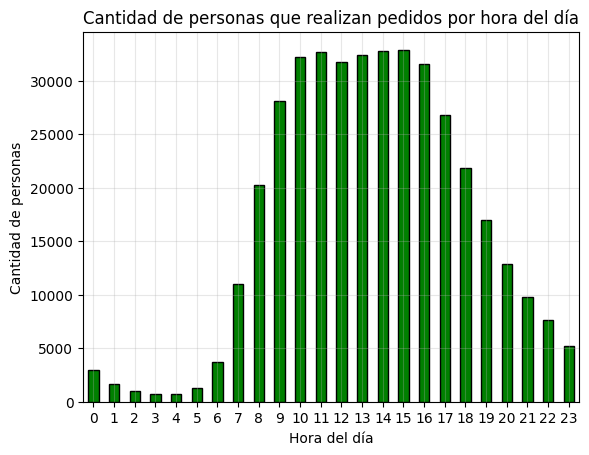

In [38]:
datos_tabla = df_orders.groupby("order_hour_of_day")["user_id"].nunique()

datos_tabla.plot(
    kind="bar",
    title="Cantidad de personas que realizan pedidos por hora del día",
    color="green",
    xlabel="Hora del día",
    ylabel="Cantidad de personas",
    legend=False,
    rot=0,
    edgecolor="black"
)

plt.grid(alpha=0.3)
plt.show()

La gráfica muestra que la mayor cantidad de pedidos se concentra entre las 9:00 a.m. y las 4:00 p.m., alcanzando su punto máximo alrededor de las 10:00 a.m. En contraste, durante la madrugada se registra una actividad considerablemente menor, especialmente entre las 2:00 a.m. y las 5:00 a.m. Esto sugiere que los usuarios realizan la mayoría de sus compras durante las horas diurnas y de mayor actividad cotidiana.

### [A3] ¿Qué día de la semana compran víveres las personas?

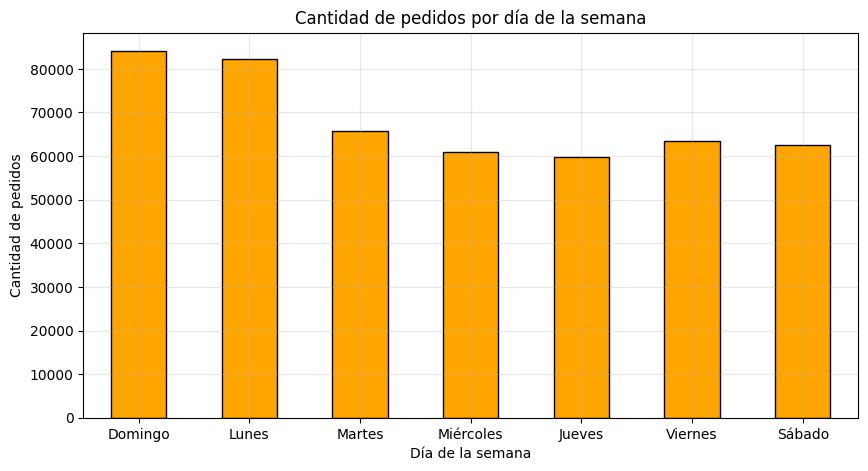

In [39]:

dias = [
    "Domingo", "Lunes", "Martes",
    "Miércoles", "Jueves", "Viernes", "Sábado"
]



datos_tabla2 = df_orders["order_dow"].value_counts().sort_index()


datos_tabla2.index = dias

datos_tabla2.plot(
    kind="bar",
    figsize=(10, 5),
    color="orange",
    title="Cantidad de pedidos por día de la semana",
    xlabel="Día de la semana",
    ylabel="Cantidad de pedidos",
    legend=False,
    rot=0,
    edgecolor="black"
)
plt.grid(alpha=0.3)
plt.show()


La gráfica muestra que la mayor cantidad de pedidos se realiza los domingos y lunes, mientras que entre martes y jueves la actividad disminuye moderadamente. Esto sugiere que los usuarios tienden a concentrar sus compras al inicio de la semana o durante el fin de semana, posiblemente como parte de la planificación de sus compras semanales.


### [A4] ¿Cuánto tiempo esperan las personas hasta hacer otro pedido? Comenta sobre los valores mínimos y máximos.

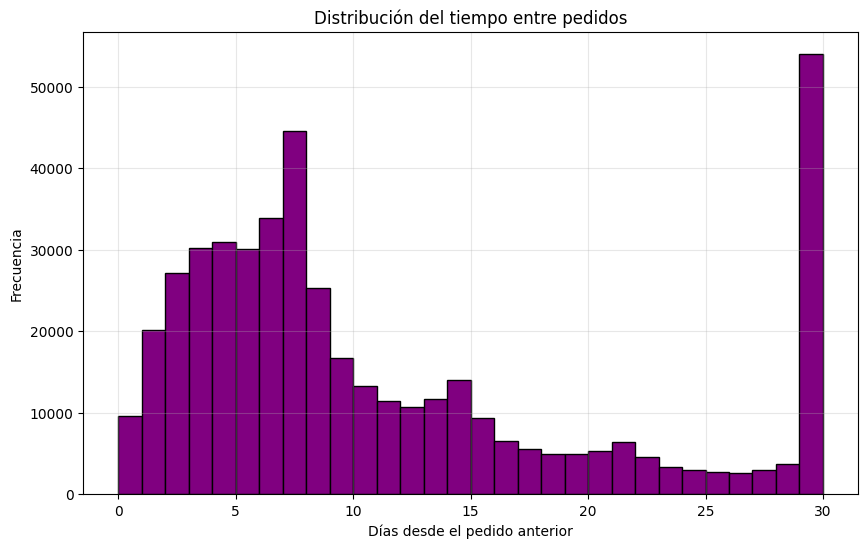

Estadísticas de días entre pedidos:
Mínimo: 0.0 días
Máximo: 30.0 días
Promedio: 11.1 días
Mediana: 7.0 días


In [40]:
tiempo_espera = df_orders['days_since_prior_order']
tiempo_espera.plot(kind="hist",bins=30, figsize=(10, 6), color="purple", edgecolor="black")
plt.grid(alpha=0.3)
plt.title("Distribución del tiempo entre pedidos")
plt.xlabel("Días desde el pedido anterior")
plt.ylabel("Frecuencia")
plt.show()
print("Estadísticas de días entre pedidos:")
print(f"Mínimo: {tiempo_espera.min()} días")
print(f"Máximo: {tiempo_espera.max()} días")
print(f"Promedio: {tiempo_espera.mean():.1f} días")
print(f"Mediana: {tiempo_espera.median()} días")

La distribución muestra que la mayoría de los clientes realizan nuevos pedidos dentro de los primeros 10 días después de una compra anterior, con una alta concentración alrededor de los 7 días. Además, se observa un pico importante en los 30 días, lo que sugiere que muchos usuarios tienen hábitos de compra mensuales. En general, los resultados indican patrones de compra recurrentes y relativamente frecuentes dentro de la plataforma.


# [B] Intermedio (deben completarse todos para aprobar)

1. ¿Existe alguna diferencia entre las distribuciones `'order_hour_of_day'` de los miércoles y los sábados? Traza gráficos de barra de `'order_hour_of_day'` para ambos días en la misma figura y describe las diferencias que observes.
2. Grafica la distribución para el número de órdenes que hacen los clientes (es decir, cuántos clientes hicieron solo 1 pedido, cuántos hicieron 2, cuántos 3, y así sucesivamente...).
3. ¿Cuáles son los 20 principales productos que se piden con más frecuencia (muestra su identificación y nombre)?

### [B1] Diferencia entre miércoles y sábados para  `'order_hour_of_day'`. Traza gráficos de barra para los dos días y describe las diferencias que veas.

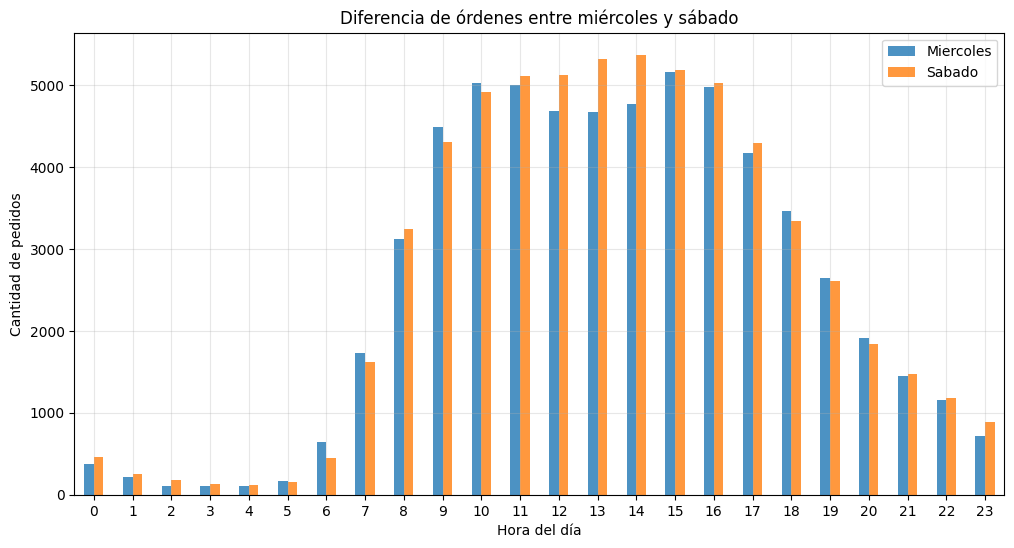

In [41]:
pedidos_miercoles = df_orders[
    df_orders["order_dow"] == 3
]["order_hour_of_day"].value_counts().sort_index()

pedidos_sabado = df_orders[
    df_orders["order_dow"] == 6
]["order_hour_of_day"].value_counts().sort_index()

comparacion = pd.DataFrame({
    "Miercoles": pedidos_miercoles,
    "Sabado": pedidos_sabado
})

comparacion.plot(
    kind="bar",
    figsize=(12,6),
    title="Diferencia de órdenes entre miércoles y sábado",
    xlabel="Hora del día",
    ylabel="Cantidad de pedidos",
    rot=0,
    alpha=0.8
)

plt.grid(alpha=0.3)
plt.legend()
plt.show()

El gráfico muestra que el comportamiento de los pedidos es muy similar entre miércoles y sábado a lo largo del día. En ambos casos, la actividad comienza a aumentar significativamente desde las primeras horas de la mañana y alcanza sus niveles más altos entre las 10:00 a.m. y las 3:00 p.m.

Sin embargo, se observa que los sábados presentan una cantidad ligeramente mayor de pedidos durante las horas de mayor actividad, especialmente alrededor del mediodía y primeras horas de la tarde. Esto podría indicar una mayor concentración de compras durante el fin de semana en comparación con los días laborales.

### [B2] ¿Cuál es la distribución para el número de pedidos por cliente?

In [ ]:
df_orders.head()

In [ ]:
pedidos_por_cliente = df_orders.groupby("user_id")["order_id"].count()

pedidos_por_cliente.plot(
    kind="hist",
    bins=30,
    figsize=(10, 6),
    color="steelblue",
    edgecolor="black"
)

plt.title("Distribución del número de pedidos por cliente")
plt.xlabel("Cantidad de pedidos por cliente")
plt.ylabel("Frecuencia de clientes")

plt.grid(alpha=0.3)
plt.show()

La distribución muestra que la mayoría de los clientes realiza una cantidad relativamente baja de pedidos, mientras que solo un pequeño grupo presenta una frecuencia de compra mucho más alta. Esto indica una distribución desigual en la actividad de los usuarios, donde la mayor parte de los clientes utiliza la plataforma de forma ocasional o moderada, y pocos clientes concentran un gran volumen de pedidos.

### [B3] ¿Cuáles son los 20 productos más populares (muestra su ID y nombre)?

In [ ]:
productos_populares = df_order_products["product_id"].value_counts().head(20)

productos_populares = productos_populares.reset_index()

productos_populares.columns = ["product_id", "cantidad_pedidos"]

productos_populares = productos_populares.merge( 
    df_products[["product_id", "product_name"]],
    on="product_id"
)

productos_populares = productos_populares[
    ["product_id", "product_name", "cantidad_pedidos"]
]

print(productos_populares)


Los resultados muestran que ciertos productos concentran una cantidad significativamente mayor de pedidos en comparación con el resto, evidenciando patrones claros de preferencia entre los clientes. Además, la diferencia entre los productos más solicitados y los menos populares dentro del top 20 refleja que algunos artículos son comprados de manera recurrente y constante dentro de la plataforma.

# [C] Difícil (deben completarse todos para aprobar)

1. ¿Cuántos artículos suelen comprar las personas en un pedido? ¿Cómo es la distribución?
2. ¿Cuáles son los 20 principales artículos que vuelven a pedirse con mayor frecuencia (muestra sus nombres e IDs de los productos)?
3. Para cada producto, ¿cuál es la tasa de repetición del pedido (número de repeticiones de pedido/total de pedidos?
4. Para cada cliente, ¿qué proporción de los productos que pidió ya los había pedido? Calcula la tasa de repetición de pedido para cada usuario en lugar de para cada producto.
5. ¿Cuáles son los 20 principales artículos que la gente pone primero en sus carritos (muestra las IDs de los productos, sus nombres, y el número de veces en que fueron el primer artículo en añadirse al carrito)?

### [C1] ¿Cuántos artículos compran normalmente las personas en un pedido? ¿Cómo es la distribución?

In [ ]:
articulos_por_pedido = df_order_products.groupby("order_id")["product_id"].count()

articulos_por_pedido.plot(
    kind="hist",
    bins=30,
    figsize=(10,6),
    color="steelblue",
    edgecolor="black"
)

plt.title("Distribución de artículos por pedido")
plt.xlabel("Cantidad de artículos")
plt.ylabel("Frecuencia de pedidos")

plt.grid(alpha=0.3)
plt.show()

print(articulos_por_pedido.describe())

La distribución muestra que la mayoría de los pedidos contiene una cantidad relativamente baja de productos, mientras que los pedidos con grandes cantidades de artículos son menos frecuentes. Esto indica que la mayor parte de los usuarios realiza compras pequeñas o medianas, aunque existe un grupo reducido de clientes que hace pedidos considerablemente más grandes.

### [C2] ¿Cuáles son los 20 principales artículos que vuelven a pedirse con mayor frecuencia (muestra sus nombres e IDs de los productos)?

In [ ]:
productos_reordenados = df_order_products[df_order_products["reordered"] == 1]

top_reordenados = productos_reordenados["product_id"].value_counts().head(20)

top_reordenados = top_reordenados.reset_index()

top_reordenados.columns = ["product_id", "cantidad_reordenes"]

top_reordenados = top_reordenados.merge(
    df_products[["product_id", "product_name"]],
    on="product_id"
)

top_reordenados = top_reordenados[
    ["product_id", "product_name", "cantidad_reordenes"]
]

print(top_reordenados)

Los resultados evidencian que ciertos productos son comprados repetidamente por una gran cantidad de usuarios, lo que sugiere que se trata de artículos de consumo frecuente o de necesidad constante. Además, la diferencia entre los productos más reordenados y el resto refleja patrones claros de preferencia y fidelidad hacia determinados productos.

### [C3] Para cada producto, ¿cuál es la proporción de las veces que se pide y que se vuelve a pedir?

In [ ]:
total_pedidos = df_order_products.groupby("product_id")["order_id"].count()

repeticiones = df_order_products.groupby("product_id")["reordered"].sum()

tasa_reorden = (repeticiones / total_pedidos).reset_index()

tasa_reorden.columns = ["product_id", "tasa_reorden"]

tasa_reorden = tasa_reorden.merge(
    df_products[["product_id", "product_name"]],
    on="product_id"
)

tasa_reorden = tasa_reorden[
    ["product_id", "product_name", "tasa_reorden"]
]

tasa_reorden = tasa_reorden.sort_values(
    by="tasa_reorden",
    ascending=False
)

print(tasa_reorden)

La tasa de repetición permitió identificar qué productos tienen mayor probabilidad de ser comprados nuevamente después de un primer pedido. Los productos con tasas más altas reflejan una demanda constante y hábitos de consumo recurrentes, mientras que aquellos con tasas menores podrían representar compras más ocasionales.

### [C4] Para cada cliente, ¿qué proporción de sus productos ya los había pedido?

In [ ]:
ordenes_usuarios = df_orders[["order_id", "user_id"]]

datos_usuarios = df_order_products.merge(
    ordenes_usuarios,
    on="order_id"
)

productos_totales = datos_usuarios.groupby("user_id")["product_id"].count()

productos_reordenados = datos_usuarios.groupby("user_id")["reordered"].sum()

tasa_usuario = (productos_reordenados / productos_totales).reset_index()

tasa_usuario.columns = ["user_id", "tasa_reorden"]

print(tasa_usuario.head())

El análisis mostró que muchos usuarios tienden a volver a pedir una proporción importante de productos que ya habían comprado anteriormente. Esto sugiere comportamientos de compra repetitivos y cierta estabilidad en las preferencias de los clientes dentro de la plataforma.

### [C5] ¿Cuáles son los 20 principales artículos que las personas ponen primero en sus carritos?

In [ ]:
primeros_productos = df_order_products[
    df_order_products["add_to_cart_order"] == 1
]

top_primeros = primeros_productos["product_id"].value_counts().head(20)

top_primeros = top_primeros.reset_index()

top_primeros.columns = ["product_id", "veces_primero"]

top_primeros = top_primeros.merge(
    df_products[["product_id", "product_name"]],
    on="product_id"
)

top_primeros = top_primeros[
    ["product_id", "product_name", "veces_primero"]
]

print(top_primeros)

Los productos que aparecen con mayor frecuencia como primer artículo añadido al carrito probablemente representan compras prioritarias o artículos esenciales para los usuarios. Esto permite identificar productos con una alta relevancia dentro de la experiencia de compra y patrones comunes en el comportamiento de los clientes.

### Conclusion general del proyecto:

A lo largo del proyecto se realizó un proceso completo de exploración, limpieza y análisis de datos relacionados con los hábitos de compra de los usuarios en la plataforma Instacart. Inicialmente, se trabajó en la validación y preprocesamiento de los datos, identificando registros duplicados, valores ausentes y posibles inconsistencias en diferentes tablas. Este paso fue fundamental para asegurar que la información utilizada en el análisis fuera confiable y coherente.

Posteriormente, se desarrolló un análisis exploratorio enfocado en comprender el comportamiento de los clientes y los patrones de consumo dentro de la plataforma. Los resultados mostraron que la actividad de compra presenta tendencias claras según la hora del día y el día de la semana, concentrándose principalmente durante las horas diurnas y especialmente al inicio de la semana y los fines de semana. Además, se observó que muchos usuarios realizan pedidos de forma recurrente, con intervalos relativamente cortos entre compras, lo que evidencia hábitos de consumo frecuentes y consistentes.

El análisis de productos también permitió identificar artículos con una demanda significativamente mayor que otros, destacando productos que son comprados y reordenados de manera constante por una gran cantidad de clientes. Asimismo, se encontró que ciertos usuarios presentan tasas elevadas de repetición de pedidos, lo que sugiere fidelidad hacia determinados productos o rutinas de compra estables.

En conjunto, el proyecto permitió aplicar técnicas esenciales de análisis de datos utilizando Python y Pandas, incluyendo manipulación de DataFrames, limpieza de información, agrupación de datos, generación de estadísticas descriptivas y visualización gráfica. Más allá de los resultados obtenidos, el desarrollo de este proyecto fortaleció habilidades fundamentales para el trabajo analítico, especialmente en la interpretación de datos y la transformación de información en conclusiones útiles y comprensibles.